# Lab 1 – Your first classifier
*Session 2 · about 2 hours*

A **classifier** takes a few numbers that describe an animal (its *features*, like the characters in an
identification key) and returns a label. It *learns* its rule from labelled examples – the **training set** –
and we check it on examples it has never seen – the **test set**.

We start as small as possible: **two labels, two features**, so that everything fits in one picture.

In [1]:
# Run this cell first. On Google Colab it fetches the course; on your own computer it only loads the data.
import os, subprocess, sys
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("/content/fathomnetchallange").exists():
        if Path("/content/fathomnetchallange.zip").exists():      # zip from your tutor (drag it into Files)
            subprocess.run(["unzip", "-q", "/content/fathomnetchallange.zip", "-d", "/content"], check=True)
        else:
            subprocess.run(["git", "clone", "-q", "https://github.com/TorbenGl/fathomnetchallange",
                            "/content/fathomnetchallange"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "fathomnet"], check=True)
    os.chdir("/content/fathomnetchallange/course")
sys.path.insert(0, str(Path.cwd()))

from setup_env import setup
ROOT = setup()          # first time: downloads the crops (~15 min). setup(per_category=100) is a quick subset.

import warnings; warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from classifier_lab import data, features, models, evaluate
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

Dataset ready: /home/user/fathomnetchallange/fathomnet2025_compact  (23698 crop files; exact duplicate boxes are dropped when loading)


## 1. Two animals, two characters
*Ptychogastria polaris* is a small, reddish deep-sea jellyfish (Cnidaria). *Pyrosoma atlanticum* is a colonial
tunicate (Chordata) that looks bluish on the video. We describe every crop by two numbers:
* **redness** = mean of (red − blue) over all pixels,
* **brightness** = mean grey value.

train: 444 crops, test: 148 crops


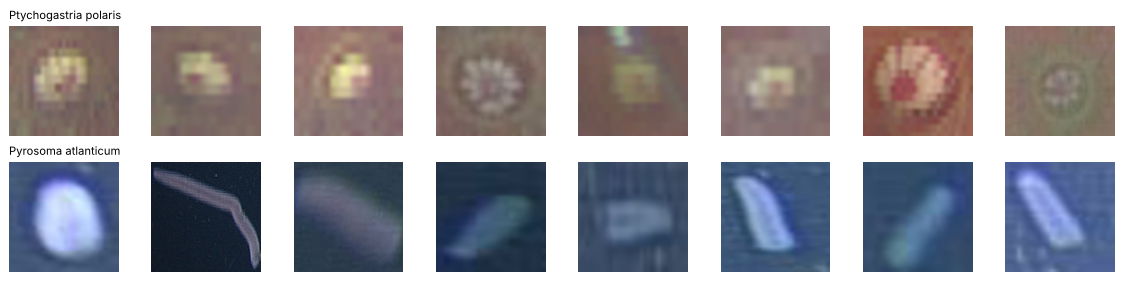

In [2]:
A, B = "Ptychogastria polaris", "Pyrosoma atlanticum"
df = data.set_target(data.load_dataset())
two = df[df["label"].isin([A, B])].reset_index(drop=True)
data.show_examples(two, labels=[A, B], n=8);

F = features.colour_stats(two)                         # 30 numbers per crop; we use two of them
names = features.COLOUR_STAT_NAMES
X2 = F[:, [names.index("redness"), names.index("brightness")]]
y2 = two["y"].to_numpy()
train, test = data.split(two, "random", seed=0)        # 75 % to learn from, 25 % to test on
tr = two["annotation_id"].isin(train["annotation_id"]).to_numpy(); te = ~tr
print(f"train: {tr.sum()} crops, test: {te.sum()} crops")

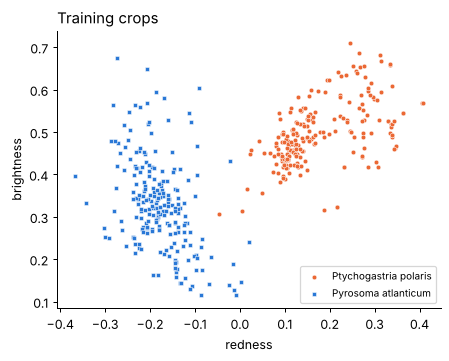

In [3]:
def scatter(ax, X, y, mask, title=""):
    for lab, col, mk in [(A, evaluate.ORANGE, "o"), (B, evaluate.BLUE, "s")]:
        m = mask & (y == lab)
        ax.scatter(X[m, 0], X[m, 1], s=14, c=col, marker=mk, label=lab, edgecolor="white", linewidth=0.4)
    ax.set_xlabel("redness"); ax.set_ylabel("brightness"); ax.set_title(title, loc="left"); ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(5.5, 4))
scatter(ax, X2, y2, tr, "Training crops")

## 2. Be the classifier
Find a rule by eye: a **threshold on redness** that separates the two animals. Change `THRESHOLD` and re-run until
the training accuracy is as high as you can get. Then – only once – look at the test accuracy.

In [4]:
THRESHOLD = 0.0          # <- your choice

def my_rule(X):
    return np.where(X[:, 0] > THRESHOLD, A, B)      # redder than the threshold -> the jellyfish

acc = lambda pred, truth: (pred == truth).mean()
print(f"training accuracy: {acc(my_rule(X2[tr]), y2[tr]):.1%}")

training accuracy: 99.3%


In [5]:
print(f"test accuracy:     {acc(my_rule(X2[te]), y2[te]):.1%}")

test accuracy:     100.0%


> ### ✍️ Q1
> Which threshold did you choose and why? Is the test accuracy higher or lower than the training accuracy? Would a sloping line (using brightness as well) be better? Sketch it on paper.

*Your answer:*

## 3. Let the computer find the rule
Three classic ways to learn a rule from examples:

| classifier | idea | biology analogy |
|---|---|---|
| **nearest centroid** | compute the *average* crop of each label; assign a new crop to the closest average | compare with the type description |
| **k-nearest neighbours (kNN)** | find the *k* most similar training crops; majority vote | compare with the reference collection |
| **decision tree** | a sequence of yes/no questions on single features | a dichotomous identification key |

The coloured background shows which label the classifier would give to every possible point – its **decision regions**.
The line between regions is the **decision boundary**.

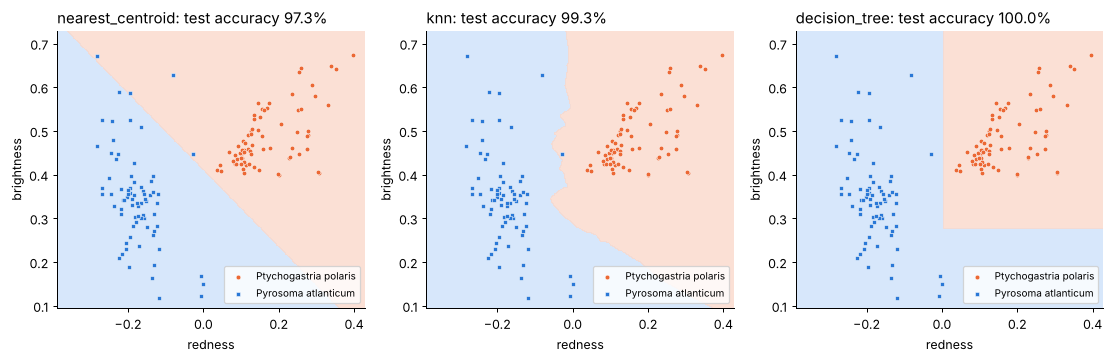

In [6]:
def regions(ax, clf, X):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .02, X[:, 0].max() + .02, 300),
                         np.linspace(X[:, 1].min() - .02, X[:, 1].max() + .02, 300))
    z = clf.predict(np.c_[xx.ravel(), yy.ravel()]) == A
    ax.contourf(xx, yy, z.reshape(xx.shape), levels=[-.5, .5, 1.5], colors=["#cde2fb", "#fbd9cb"], alpha=.8)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name, kw in zip(axes, ["nearest_centroid", "knn", "decision_tree"], [{}, {"k": 5}, {"max_depth": 2}]):
    clf = models.make(name, **kw).fit(X2[tr], y2[tr])
    regions(ax, clf, X2)
    scatter(ax, X2, y2, te, f"{name}: test accuracy {acc(clf.predict(X2[te]), y2[te]):.1%}")

## 4. Overfitting: learning the collection by heart
The jellyfish and the tunicate were easy. Now a pair that colour alone separates badly: **sea stars (Asteroidea)
and brittle stars (Ophiuroidea)**. kNN with **k = 1** copies the label of the single most similar training crop.
On the training set it is always right (every crop is its own nearest neighbour). Is it also the best on new crops?

,train accuracy,test accuracy
k,,
1,100.0%,68.7%
3,83.6%,71.3%
5,80.2%,67.3%
11,75.1%,70.7%
25,69.8%,77.3%
51,67.8%,81.3%
101,68.4%,78.7%


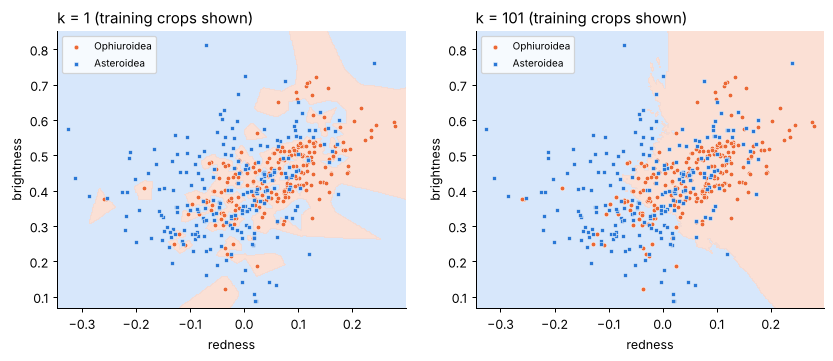

In [7]:
A, B = "Ophiuroidea", "Asteroidea"
hard = df[df["label"].isin([A, B])].reset_index(drop=True)
Fh = features.colour_stats(hard)
Xh = Fh[:, [names.index("redness"), names.index("brightness")]]
yh = hard["y"].to_numpy()
trh = hard["annotation_id"].isin(data.split(hard, "random", seed=0)[0]["annotation_id"]).to_numpy(); teh = ~trh

rows = []
for k in [1, 3, 5, 11, 25, 51, 101]:
    clf = models.make("knn", k=k).fit(Xh[trh], yh[trh])
    rows.append({"k": k, "train accuracy": acc(clf.predict(Xh[trh]), yh[trh]), "test accuracy": acc(clf.predict(Xh[teh]), yh[teh])})
display(pd.DataFrame(rows).set_index("k").style.format("{:.1%}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, k in zip(axes, [1, 101]):
    clf = models.make("knn", k=k).fit(Xh[trh], yh[trh])
    regions(ax, clf, Xh); scatter(ax, Xh, yh, trh, f"k = {k} (training crops shown)")

> ### ✍️ Q2
> Describe the decision regions for k = 1 and k = 101. Which one has *learned the collection by heart*? This is called **overfitting**. Why is the training accuracy useless for judging a classifier?

*Your answer:*

## 5. A decision tree is an identification key
A decision tree asks one yes/no question per step. Here is the tree learned from the two features:

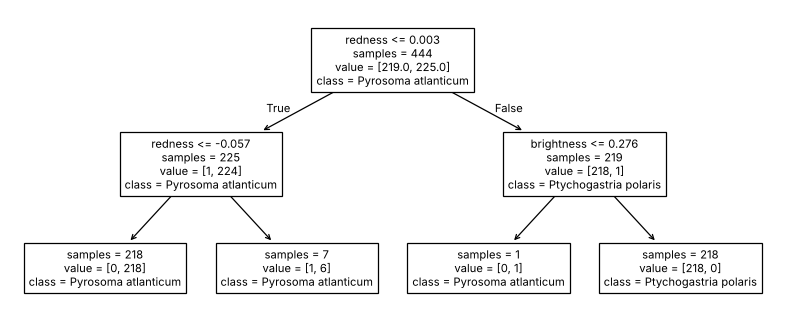

In [8]:
from sklearn.tree import plot_tree
A, B = "Ptychogastria polaris", "Pyrosoma atlanticum"     # back to the easy pair
tree = models.make("decision_tree", max_depth=2).fit(X2[tr], y2[tr])
fig, ax = plt.subplots(figsize=(11, 4.5))
plot_tree(tree, feature_names=["redness", "brightness"], class_names=list(tree.classes_), filled=False,
          impurity=False, proportion=False, ax=ax, fontsize=9);

Now trees of growing depth on the **hard pair** (sea stars vs brittle stars):

In [9]:
rows = []
for depth in [1, 2, 3, 5, 8, 12, None]:
    t = models.make("decision_tree", max_depth=depth).fit(Xh[trh], yh[trh])     # the hard pair
    rows.append({"max_depth": str(depth), "leaves": t.get_n_leaves(),
                 "train accuracy": acc(t.predict(Xh[trh]), yh[trh]), "test accuracy": acc(t.predict(Xh[teh]), yh[teh])})
pd.DataFrame(rows).set_index("max_depth").style.format({"train accuracy": "{:.1%}", "test accuracy": "{:.1%}"})

,leaves,train accuracy,test accuracy
max_depth,,,
1,2,66.7%,70.0%
2,4,67.8%,71.3%
3,8,67.8%,67.3%
5,24,77.3%,76.7%
8,66,86.9%,68.7%
12,106,96.9%,64.0%
None,123,100.0%,65.3%


> ### ✍️ Q3
> Read the depth-2 tree above like a key: write it as a dichotomous key (1a/1b, 2a/2b …). What happens to train and test accuracy when the tree for the hard pair gets deeper? Would a taxonomist write a key with hundreds of couplets that each fit one single specimen?

*Your answer:*

## 6. From 2 to 79 labels, from 2 to 30 features
Real life is harder. We now use **all 30 colour/texture features** and ask for the **phylum** (7 answers) and then
for the **label** (79 answers). The **majority** classifier always says the most common answer – the baseline
that every real classifier must beat.

In [10]:
full = data.set_target(data.load_dataset(), "phylum")
Xf = features.colour_stats(full)
train, test = data.split(full, "random", seed=0)
tr = full["annotation_id"].isin(train["annotation_id"]).to_numpy()
rows = []
for target in ["phylum", "label"]:
    y = full[target].to_numpy()
    for name in ["majority", "nearest_centroid", "knn", "decision_tree"]:
        res, _ = evaluate.run(models.make(name, max_depth=12), Xf[tr], y[tr], Xf[~tr], y[~tr])
        rows.append({"target": target, "name": name, "test accuracy": res["accuracy"], "train accuracy": res["train_accuracy"]})
table = pd.DataFrame(rows).pivot(index="name", columns="target", values=["test accuracy", "train accuracy"])
table.style.format("{:.1%}")

> ### ✍️ Q4
> How much better than the majority baseline is the best classifier, for phyla and for labels? Is 7-phylum classification really 'easier' – or is the baseline just higher? Why do you think colour features alone are not enough for 79 labels?

*Your answer:*

## Summary
* A classifier = features + a rule learned from a training set.
* Judge it **only on a test set** it has not seen. Training accuracy measures memory, not skill.
* Flexible rules (k = 1, deep trees) can **overfit**.
* Always compare with a **baseline**.

Next lab: better features – including what a neural network "sees".